## EDA


In [1]:
# Import libraries

import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import train_test_split

import matplotlib
matplotlib.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')


In [2]:
# Path

PROC = pathlib.Path('../data/processed/red_wine_cleaned.csv')


In [3]:
df = pd.read_csv(PROC)
print(df.shape)
df.head(2)


(1359, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.0,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5


### Quality distribution and what shifts with the score


In [4]:
print(df['quality'].value_counts().sort_index())

by_quality = df.groupby('quality').agg(
    n=('quality', 'size'),
    alcohol=('alcohol', 'mean'),
    volatile_acidity=('volatile acidity', 'mean'),
    sulphates=('sulphates', 'mean'),
    density=('density', 'mean'),
).round(3)
display(by_quality)

print("Higher-scored wines tend to carry more alcohol and less volatile acidity.")


quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


,n,alcohol,volatile_acidity,sulphates,density
quality,,,,,
3,10,9.955,0.885,0.570,0.997
4,53,10.265,0.694,0.596,0.997
5,577,9.889,0.579,0.624,0.997
6,535,10.659,0.496,0.675,0.997
7,167,11.491,0.404,0.743,0.996
8,17,12.159,0.428,0.775,0.995


Higher-scored wines tend to carry more alcohol and less volatile acidity.


### Feature behaviour across quality bands


quality_band
<=5    640
6      535
>=7    184
Name: count, dtype: int64


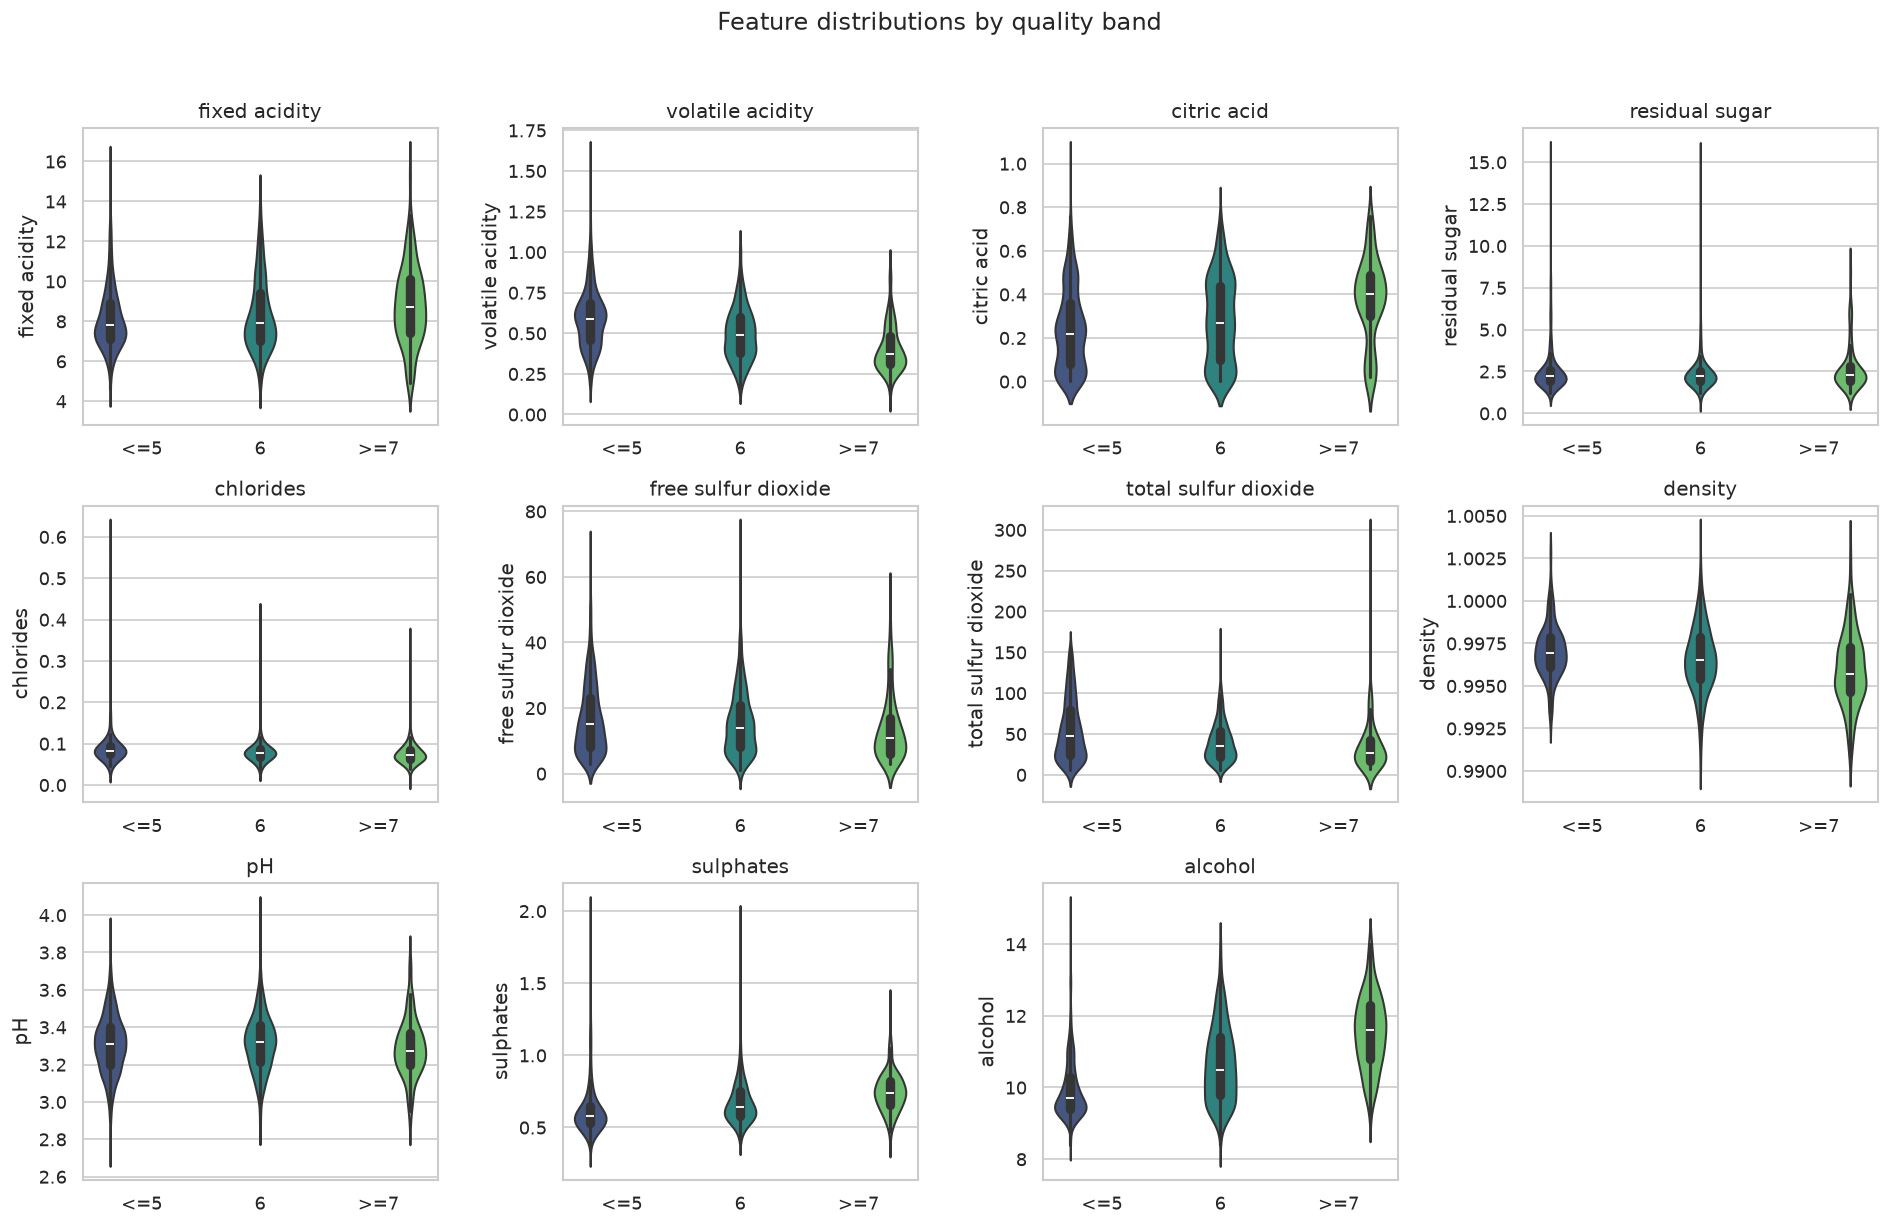

In [5]:
df['quality_band'] = pd.cut(df['quality'], bins=[2, 5, 6, 8], labels=['<=5', '6', '>=7'])
print(df['quality_band'].value_counts())

num_cols = [c for c in df.columns if c not in ['quality', 'quality_band']]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), num_cols):
    sns.violinplot(
        data=df,
        x='quality_band',
        y=col,
        hue='quality_band',
        palette='viridis',
        legend=False,
        ax=ax,
    )
    ax.set(xlabel='', title=col)
for ax in axes.ravel()[len(num_cols):]:
    ax.set_visible(False)
plt.suptitle('Feature distributions by quality band', y=1.02)
plt.tight_layout()
plt.show()


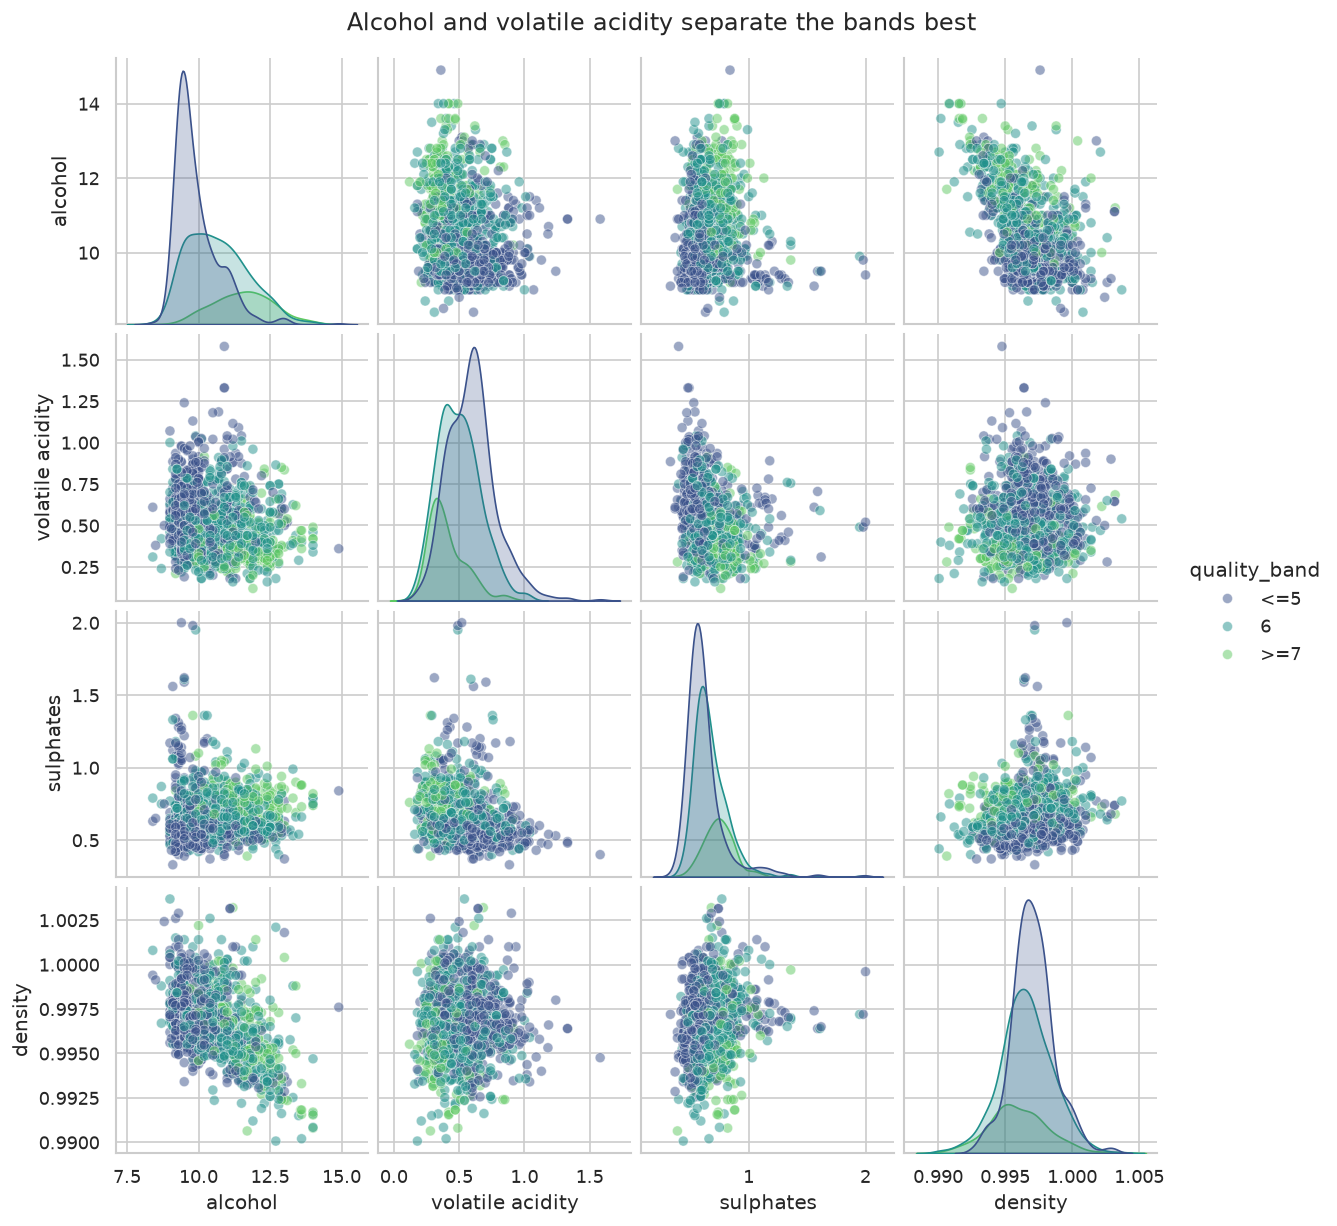

In [6]:
# Pairplot for four informative measurements - avoids an 11 x 11 grid

sns.pairplot(
    df,
    vars=['alcohol', 'volatile acidity', 'sulphates', 'density'],
    hue='quality_band',
    palette='viridis',
    diag_kind='kde',
    plot_kws={'alpha': 0.5},
)
plt.suptitle('Alcohol and volatile acidity separate the bands best', y=1.02)
plt.show()


### Mutual information ranking


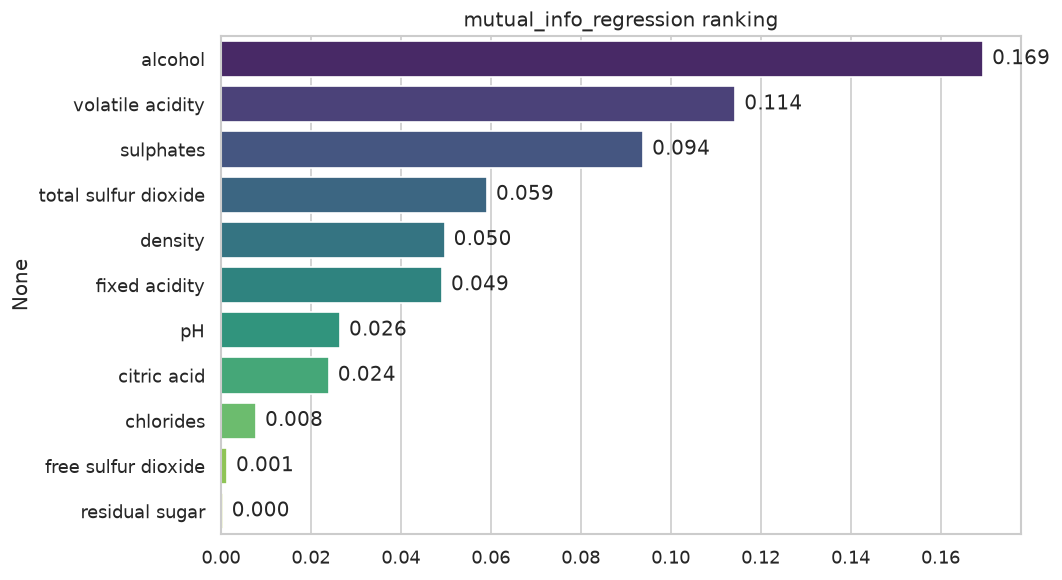

,mi
alcohol,0.169466
volatile acidity,0.114373
sulphates,0.093872
total sulfur dioxide,0.059154
density,0.049737
fixed acidity,0.049156
pH,0.026476
citric acid,0.023990
chlorides,0.007815
free sulfur dioxide,0.001357


In [7]:
X = df[num_cols].copy()
y = df['quality']

mi = mutual_info_regression(X, y, random_state=42)
mi_s = pd.Series(mi, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=mi_s.values, y=mi_s.index, hue=mi_s.index, palette='viridis', legend=False)
plt.title('mutual_info_regression ranking')
for i, v in enumerate(mi_s.values):
    plt.text(v + 0.002, i, f"{v:.3f}", va='center')
plt.tight_layout()
plt.show()
display(mi_s.to_frame('mi'))


### Outlier clipping demo, fitted on train only


In [8]:
train, test = train_test_split(df, test_size=0.2, random_state=42)
for col in ['residual sugar', 'total sulfur dioxide']:
    q1, q3 = train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    hi = q3 + 1.5 * iqr
    print(f"{col}: train hi clip {hi:.2f} - test beyond hi: {(test[col] > hi).mean():.1%}")

# Decision: no clipping. The Pipeline in 03 imputes and scales with train-fold statistics only.


residual sugar: train hi clip 3.65 - test beyond hi: 11.8%
total sulfur dioxide: train hi clip 124.50 - test beyond hi: 3.3%
